Test the slab model with 2 islands. Fig.15 (b):
$$
\begin{align*}
&m_1=2\;,\;m_2=1\;,\;n_1=-n_2=1\\
&\delta_1=\delta_2 =0.05\\
&\iota'=2
\end{align*}
$$

In [1]:
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
from fields.slab_bfield_two_pert import SlabBfieldTwoPert
from pyoculus.maps import ToroidalBfieldSection
from pyoculus.solvers import PoincarePlot, FixedPoint, Manifold
import matplotlib.pyplot as plt

C:\Users\mirei\OneDrive - epfl.ch\MA3\pyoculus\pyoculus\maps\tokamap.py:114: SyntaxWarning: invalid escape sequence '\p'
  - w_0: float, the safety factor at the "axis" \psi or y = 0
C:\Users\mirei\OneDrive - epfl.ch\MA3\pyoculus\pyoculus\maps\standard_map.py:93: SyntaxWarning: invalid escape sequence '\p'
  - w_0: float, the safety factor at the "axis" \psi or y = 0


#### Create the magnetic field:

In [2]:
field = SlabBfieldTwoPert(
    m1=2,
    n1=1,
    delta1=0.05,
    m2=1,
    n2=-1,
    delta2=0.05,
    iota_prime=2.0,
    x0=1.0,
)

xs1 = field.x0 + field.n1 / (field.iota_prime * field.m1)
xs2 = field.x0 + field.n2 / (field.iota_prime * field.m2)

print("The islands will be situated at x_s =", xs1, xs2)

The islands will be situated at x_s = 1.25 0.5


#### Create the map:

In [3]:
map = ToroidalBfieldSection(field, domain=[(0, 2), (0, 2*np.pi)])

#### Create Poincaré plot:

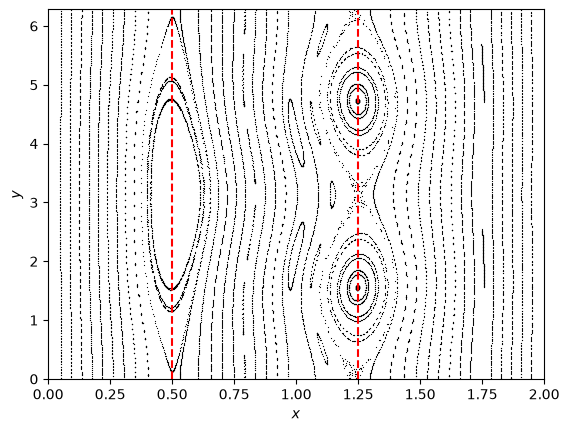

In [4]:
pplot = PoincarePlot.with_segments(
    map,
    np.array([
        [0.05, np.pi/2],
        [1.95, np.pi/2],
        [0.05, 3*np.pi/2],
        [1.95, 3*np.pi/2]
    ]),
    neps=[50, 50],
    connected=False,
)

# Follow each initial condition for 200 crossings
pplot.compute(npts=150)

# Plot directly in (x,y) coordinates
fig, ax = pplot.plot(plottype=None) # plottypeNone to directly plot in the coordinates of the map

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim(0, 2)
ax.set_ylim(0, 2*np.pi)

ax.axvline(
    xs1,
    linestyle="--",
    label=rf"$x_s1={xs1:.3f}$",
    color="r"
)
ax.axvline(
    xs2,
    linestyle="--",
    label=rf"$x_s2={xs2:.3f}$",
    color="r"
)
plt.show()

#### Find fixed points:

(<Figure size 640x480 with 1 Axes>, <Axes: >)

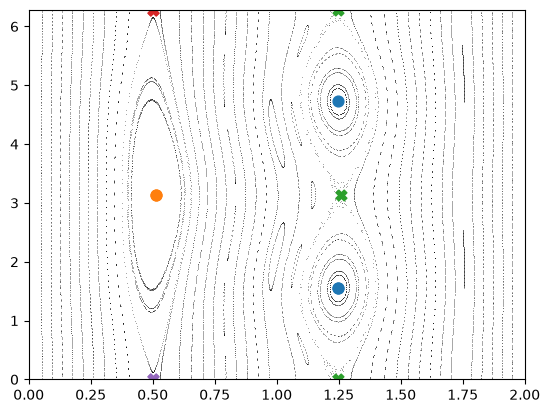

In [5]:
fig, ax = pplot.plot(
    s=0.5,
    xlim=[0, 2],
    ylim=[0, 2*np.pi],
    plottype=None
)


fp = FixedPoint(map)

# Elliptic fixed points / O-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([xs1, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(
    n = field.n2,
    m = field.m2,
    guess = np.array([xs2, 3]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

# Hyperbolic fixed points / X-points:
result = fp.find_with_iota(
    n = field.n1,
    m = field.m1,
    guess = np.array([xs1, 0.]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find_with_iota(     
    n = field.n2,
    m = field.m2,
    guess = np.array([0.5, 0.01]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

result = fp.find(   # The FP (0.5, 0.0) can only be found with fint(t=1)
    t = 1,
    guess = np.array([0.49, 0.0]),
    method="scipy.root"
)   

fp.plot(
    fig=fig,
    ax=ax,
    s=60,
    plottype=None
)

The X-points corresponding to one same island have been found in one go for the right (1) island chain, but in 2 different searches in the left (2) island. All the fixed points have been found with ```find_with_iota()``` except for (0.5,0.0), for which I had to use ```find(t=1)```.

#### Find manifolds

In [44]:
fp1 = FixedPoint(map)
fp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 0.0]), method="scipy.root")   

fp2 = FixedPoint(map)
fp2.find_with_iota(n = field.n1, m = field.m1, guess = np.array(fp1.coords[1]), method="scipy.root")  

fp3 = FixedPoint(map)
fp3.find_with_iota(n = field.n1, m = field.m1, guess = np.array(fp1.coords[2]), method="scipy.root")  

fp4 = FixedPoint(map)
fp4.find_with_iota(n = field.n2, m = field.m2, guess = np.array([0.5, 0.0]), method="scipy.root")  

fp5 = FixedPoint(map)
fp5.find(t = 1, guess = np.array([0.5, 0.0]), method="scipy.root")  

ofp1 = FixedPoint(map)
ofp1.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 4]), method="scipy.root")

ofp2 = FixedPoint(map)
ofp2.find_with_iota(n = field.n1, m = field.m1, guess = np.array([xs1, 2]), method="scipy.root")

ofp3 = FixedPoint(map)
ofp3.find_with_iota(n = field.n2, m = field.m2, guess = np.array([xs2, 3]), method="scipy.root")

In [48]:
fp2.coords

array([[1.26052331, 3.14159265],
       [1.24579374, 6.28318531],
       [1.26052331, 3.14159265]])

In [79]:
manifold1 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0]
)
manifold2 = Manifold(
    map, fp1, fp2,
    dir1=ofp1.coords[0] - fp1.coords[0],
    dir2=ofp1.coords[0] - fp2.coords[0],
    first_stable=False
)
manifold3 = Manifold(
    map, fp2, fp3,
    dir1=ofp2.coords[0] - fp2.coords[0],
    dir2=ofp2.coords[0] - fp3.coords[0]
)
manifold4 = Manifold(
    map, fp2, fp3,
    dir1=ofp2.coords[0] - fp2.coords[0],
    dir2=ofp2.coords[0] - fp3.coords[0],
    first_stable=False
)
manifold5 = Manifold(
    map, fp4, fp5,
    dir1=ofp3.coords[0] - fp4.coords[0],
    dir2=ofp3.coords[0] - fp5.coords[0]
)
manifold6 = Manifold(
    map, fp4, fp5,
    dir1=ofp3.coords[0] - fp4.coords[0],
    dir2=ofp3.coords[0] - fp5.coords[0],
    first_stable=False
)

In [80]:
for i, manifold in enumerate([manifold1, manifold2, manifold3, manifold4, manifold5, manifold6], start=1):
    manifold.vector_s = np.real_if_close(manifold.vector_s)
    manifold.vector_u = np.real_if_close(manifold.vector_u)

In [81]:
manifold1.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.5e-3)
manifold1.compute_adaptive(tol=5e-3, n_u_extra=0, n_s_extra=-1)
    
manifold2.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6, ERR=1.5e-3)
manifold2.compute_adaptive(tol=5e-3,  n_u_extra=0, n_s_extra=-1)

Failed to refine clinic at eps_s=5.137419763675015e-08, eps_u=2.040334743810208e-09: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with expensive=True to perform a more global search around the initial guess.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Failed to refine clinic at eps_s=1.8327074098915197e-08, eps_u=5.929714564393699e-09: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with expensive=True to perform a more global search around the initial guess.
Failed to refine clinic at eps_s=2.964743066821342e-08, eps_u=3.6008137292360635e-09: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with expensive=True to perform a more global search around the initial guess.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted cl

(array([[1.26052329, 3.14159274],
        [1.26052328, 3.14159282],
        [1.26052325, 3.14159295],
        [1.26052321, 3.1415932 ],
        [1.26052313, 3.14159367],
        [1.26052298, 3.14159452],
        [1.26052271, 3.1415961 ],
        [1.26052222, 3.14159899],
        [1.26052212, 3.14160058],
        [1.26052111, 3.14160726],
        [1.26051927, 3.14161956],
        [1.26051587, 3.14164222],
        [1.26050961, 3.14168397],
        [1.26049807, 3.14176088],
        [1.26047681, 3.14190256],
        [1.26046906, 3.14195427],
        [1.26042338, 3.14225875],
        [1.26033923, 3.14281967],
        [1.26018419, 3.14385304],
        [1.25989851, 3.14575676],
        [1.25937208, 3.14926388],
        [1.25840175, 3.15572482],
        [1.25804754, 3.15808227],
        [1.25595999, 3.17196559],
        [1.25210924, 3.19753568],
        [1.24500945, 3.24459816],
        [1.23197963, 3.33101168],
        [1.20856489, 3.48839336],
        [1.20042183, 3.54437236],
        [1.191

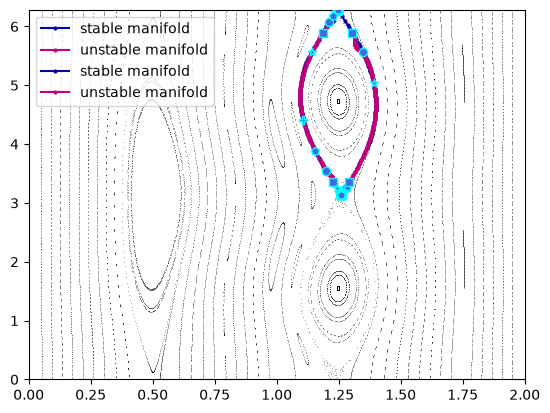

In [82]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], ylim=[0., 2*np.pi], plottype=None)

manifold1.plot("both", ax=ax)
manifold1.plot_clinics(ax=ax)
manifold2.plot("both", ax=ax)
manifold2.plot_clinics(ax=ax)
# manifold3.plot("both", ax=ax)
# manifold3.plot_clinics(ax=ax)
# manifold4.plot("both", ax=ax)
# manifold4.plot_clinics(ax=ax)
ax.legend(loc="upper left")

In [83]:
manifold3.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold3.compute_adaptive(tol=5e-3, n_u_extra=0, n_s_extra=-1)

manifold4.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold4.compute_adaptive(tol=5e-3, n_u_extra=0, n_s_extra=-1)

Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Failed to refine clinic at eps_s=2.0148457825956345e-08, eps_u=4.583809380958744e-09: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with expensive=True to perform a more global search around the initial guess.
Failed to refine clinic at eps_s=2.4333499043228208e-08, eps_u=3.425231576003694e-09: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with expensive=True to perform a more global search around the initial guess.
Failed to refine clinic at eps_s=6.153295314372685e-09, eps_u=1.7418952879502446e-08: Root finding did not converge without expensive solve, cannot find clinic point. Consider trying with expensive=True to perform a more global search around the initial guess.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Failed to

(array([[1.24579372e+00, 8.78528563e-08],
        [1.24579371e+00, 1.60546930e-07],
        [1.24579368e+00, 2.94467239e-07],
        [1.24579364e+00, 5.41181288e-07],
        [1.24579356e+00, 9.95689064e-07],
        [1.24579342e+00, 1.83300384e-06],
        [1.24579315e+00, 3.37554298e-06],
        [1.24579266e+00, 6.21727832e-06],
        [1.24579253e+00, 7.64422218e-06],
        [1.24579152e+00, 1.40454011e-05],
        [1.24578966e+00, 2.58379421e-05],
        [1.24578623e+00, 4.75626928e-05],
        [1.24577990e+00, 8.75850069e-05],
        [1.24576826e+00, 1.61315909e-04],
        [1.24574681e+00, 2.97146263e-04],
        [1.24573869e+00, 3.48580530e-04],
        [1.24569260e+00, 6.40478732e-04],
        [1.24560768e+00, 1.17822609e-03],
        [1.24545124e+00, 2.16888596e-03],
        [1.24516301e+00, 3.99391408e-03],
        [1.24463196e+00, 7.35602019e-03],
        [1.24365347e+00, 1.35496449e-02],
        [1.24328295e+00, 1.58945208e-02],
        [1.24117962e+00, 2.9202546

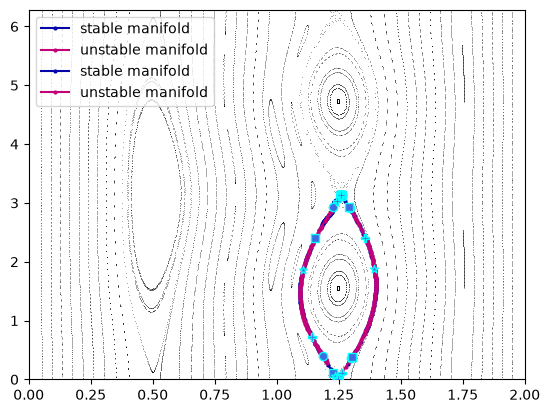

In [84]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], ylim=[0., 2*np.pi], plottype=None)

# manifold1.plot("both", ax=ax)
# manifold1.plot_clinics(ax=ax)
# manifold2.plot("both", ax=ax)
# manifold2.plot_clinics(ax=ax)
manifold3.plot("both", ax=ax)
manifold3.plot_clinics(ax=ax)
manifold4.plot("both", ax=ax)
manifold4.plot_clinics(ax=ax)
ax.legend(loc="upper left")

In [85]:
manifold5.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold5.compute_adaptive(tol=5e-3, n_u_extra=0, n_s_extra=-1)

manifold6.find_clinics_exhaustive(first_guess_eps_s=1e-6, first_guess_eps_u=1e-6)
manifold6.compute_adaptive(tol=5e-3, n_u_extra=0, n_s_extra=-1)

Shifted clinic by (0, -1) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Failed to refine clinic at eps_s=3.4854079282361273e-07, eps_u=1.1691967009966319e-07: in recalculating shifted clinic it escaped the fundamental domain.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Shifted clinic by (-1, 0) iterations to the fundamental domain.
Homo/heteroclinic recorded and ordered.
Failed to refine clinic at eps_s=1.347205882031062e-07, eps_u=3.0554155348421024e-07: Failed to find a solution within the maximum number of iterations
Failed

(array([[4.99814800e-01, 3.98543695e-07],
        [4.99814793e-01, 4.74506603e-07],
        [4.99814784e-01, 5.64948133e-07],
        [4.99814773e-01, 6.72627928e-07],
        [4.99814761e-01, 8.00831621e-07],
        [4.99814746e-01, 9.53471093e-07],
        [4.99814728e-01, 1.13520383e-06],
        [4.99814707e-01, 1.35157505e-06],
        [4.99814742e-01, 1.28549620e-06],
        [4.99814724e-01, 1.53052173e-06],
        [4.99814702e-01, 1.82224940e-06],
        [4.99814676e-01, 2.16958072e-06],
        [4.99814645e-01, 2.58311380e-06],
        [4.99814608e-01, 3.07546678e-06],
        [4.99814564e-01, 3.66166283e-06],
        [4.99814618e-01, 3.08578622e-06],
        [4.99814576e-01, 3.67397523e-06],
        [4.99814526e-01, 4.37427367e-06],
        [4.99814466e-01, 5.20804987e-06],
        [4.99814395e-01, 6.20074482e-06],
        [4.99814310e-01, 7.38264859e-06],
        [4.99814209e-01, 8.78982467e-06],
        [4.99814323e-01, 7.26093734e-06],
        [4.99814225e-01, 8.6449788

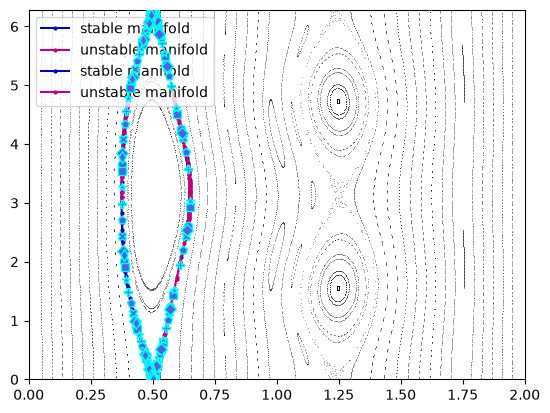

In [86]:
fig, ax = pplot.plot(marker=".", s=0.5, xlim=[.0, 2.], ylim=[0., 2*np.pi], plottype=None)

manifold5.plot("both", ax=ax)
manifold5.plot_clinics(ax=ax)
manifold6.plot("both", ax=ax)
manifold6.plot_clinics(ax=ax)
ax.legend(loc="upper left")